# Predicción de fallas del sistema de aire (APS) en camiones Scania

**Pregunta:** ¿qué camiones conviene mandar a revisión para minimizar el costo total?

**Datos:** [APS Failure at Scania Trucks](https://archive.ics.uci.edu/dataset/414/ida2016challenge) (UCI, licencia CC BY 4.0). Datos de camiones en uso diario, con variables anonimizadas. Train: 60.000 camiones (1,7% con falla). Test: 16.000.

**Costos (oficiales del desafío IDA 2016):**
- Revisión innecesaria (falso positivo): **10**
- Falla no detectada (falso negativo): **500**

Costo total = 10 × falsos positivos + 500 × falsos negativos.

**Enfoque:** LightGBM sin ajustes especiales; el umbral de decisión se elige minimizando el costo con predicciones fuera de muestra del train, y el test se usa una sola vez por corrida, al final, con el umbral ya fijado.

**Resultado:** costo total medio en test de 8.580 (rango 7.930-9.360 en 5 semillas), contra 156.250 revisando todos los camiones y 187.500 sin revisar ninguno.

## 1. Carga de datos
Los valores faltantes vienen escritos como `na`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix

COST_FP = 10    # revisión innecesaria
COST_FN = 500   # falla no detectada

In [2]:
def load_aps(path):
    """Lee el CSV saltando las líneas de licencia que pueda tener al inicio."""
    with open(path, encoding="utf-8") as f:
        skip = next(i for i, line in enumerate(f) if line.startswith("class"))
    return pd.read_csv(path, skiprows=skip, na_values="na")

train = load_aps("../data/aps_failure_training_set.csv")
test = load_aps("../data/aps_failure_test_set.csv")
print("train:", train.shape, "| test:", test.shape)

train: (60000, 171) | test: (16000, 171)


In [3]:
# Verificación: el test debe traer las etiquetas (neg / pos)
print(test["class"].value_counts(dropna=False))
assert test["class"].notna().all(), "El test no trae etiquetas: no se puede evaluar con él."

y_train = (train["class"] == "pos").astype(int)
y_test = (test["class"] == "pos").astype(int)
X_train = train.drop(columns="class")
X_test = test.drop(columns="class")

class
neg    15625
pos      375
Name: count, dtype: int64


## 2. Exploración rápida

In [4]:
print(f"Fallas en train: {y_train.sum():,} de {len(y_train):,} ({y_train.mean():.2%})")
print(f"Fallas en test:  {y_test.sum():,} de {len(y_test):,} ({y_test.mean():.2%})")

Fallas en train: 1,000 de 60,000 (1.67%)
Fallas en test:  375 de 16,000 (2.34%)


**Observación:** el test tiene una proporción mayor de fallas que el train (2,34% frente a 1,67%), es decir, los dos conjuntos no tienen la misma distribución. Se retoma en las conclusiones.

Columnas con más de 50% de nulos: 8 de 170


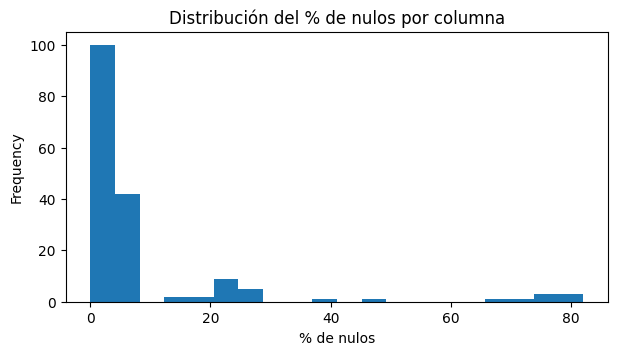

In [5]:
null_pct = (X_train.isna().mean() * 100).sort_values(ascending=False)
print(f"Columnas con más de 50% de nulos: {(null_pct > 50).sum()} de {X_train.shape[1]}")

fig, ax = plt.subplots(figsize=(7, 3.5))
null_pct.plot(kind="hist", bins=20, ax=ax, title="Distribución del % de nulos por columna")
ax.set_xlabel("% de nulos")
plt.show()

In [6]:
# ¿Los camiones con falla tienen más datos faltantes? (la ausencia puede ser informativa)
n_nulos = X_train.isna().sum(axis=1)
n_nulos.groupby(y_train.values).mean().rename({0: "sin falla", 1: "con falla"})

sin falla    13.912915
con falla    29.153000
dtype: float64

**Observación:** solo 8 de 170 columnas tienen más de 50% de nulos, pero los camiones con falla tienen en promedio más del doble de valores faltantes por fila (29,2 frente a 13,9). La ausencia de datos parece informativa (es una asociación; no se investigó la causa), lo que respalda no imputar y dejar que LightGBM maneje los nulos de forma nativa.

## 3. Modelo
LightGBM maneja los nulos de forma nativa, así que no se imputa. Con solo 1.000 fallas en train, separar un 20% como validación dejaría ~200: muy pocas para elegir un umbral con estabilidad. Por eso se usan **predicciones fuera de muestra con validación cruzada** (5 pliegues), que aprovechan las 1.000 fallas.

In [7]:
params = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    random_state=42, n_jobs=-1, verbose=-1,
)
model = lgb.LGBMClassifier(**params)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

print(f"AUC-PR  (validación cruzada): {average_precision_score(y_train, p_oof):.4f}  (tasa base: {y_train.mean():.4f})")
print(f"AUC-ROC (validación cruzada): {roc_auc_score(y_train, p_oof):.4f}")

AUC-PR  (validación cruzada): 0.8975  (tasa base: 0.0167)
AUC-ROC (validación cruzada): 0.9890


**Lectura:** en validación cruzada el AUC-PR es de 0,8975, unas 54 veces la tasa base (0,0167), y el AUC-ROC de 0,989. No son comparables de forma directa con los de test, porque la proporción de fallas es distinta.

## 4. Elección del umbral por costo
Se prueba cada umbral y se elige el que minimiza `10 × FP + 500 × FN` sobre las predicciones fuera de muestra del train.

Umbral óptimo: 0.00126
Costo por camión en validación cruzada: 0.596


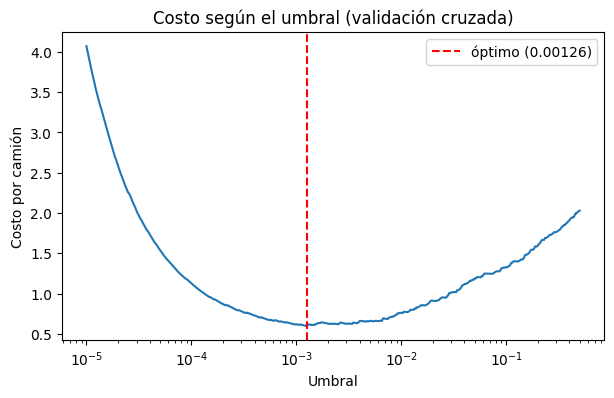

In [8]:
def total_cost(y, p, thr):
    pred = p >= thr
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    return COST_FP * fp + COST_FN * fn, fp, fn

y_tr = y_train.values
thresholds = np.logspace(-5, np.log10(0.5), 500)
costs = np.array([total_cost(y_tr, p_oof, t)[0] for t in thresholds])

best_thr = thresholds[costs.argmin()]
print(f"Umbral óptimo: {best_thr:.5f}")
print(f"Costo por camión en validación cruzada: {costs.min() / len(y_tr):.3f}")
if best_thr in (thresholds[0], thresholds[-1]):
    print("Atención: el óptimo está en el borde de la grilla; conviene ampliarla.")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs / len(y_tr))
plt.axvline(best_thr, color="red", linestyle="--", label=f"óptimo ({best_thr:.5f})")
plt.xlabel("Umbral"); plt.ylabel("Costo por camión")
plt.title("Costo según el umbral (validación cruzada)"); plt.legend(); plt.xscale("log")
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/cost_curve.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura:** el umbral óptimo es muy bajo (0,00126). Con estos costos, el punto de equilibrio de un modelo bien calibrado estaría en 10 / (10 + 500) ≈ 0,02; que el óptimo sea mucho menor sugiere que las probabilidades de LightGBM no están calibradas (hipótesis, no verificada). La grilla en escala logarítmica evita que el óptimo quede en el borde.

## 5. Resultado en test (corrida principal, semilla 42)
Se entrena con todo el train y se aplica el umbral ya elegido. Es la corrida principal; en la sección 6 se repite el procedimiento con otras semillas para medir la variación.

In [9]:
model.fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]

cost, fp, fn = total_cost(y_test.values, p_test, best_thr)
print(f"AUC-PR en test:  {average_precision_score(y_test, p_test):.4f}  (tasa base: {y_test.mean():.4f})")
print(f"AUC-ROC en test: {roc_auc_score(y_test, p_test):.4f}")
print()
print("Matriz de confusión (filas: real; columnas: predicho)")
print(pd.DataFrame(confusion_matrix(y_test, p_test >= best_thr),
                   index=["real: sin falla", "real: con falla"], columns=["pred: sin falla", "pred: con falla"]))

AUC-PR en test:  0.9339  (tasa base: 0.0234)
AUC-ROC en test: 0.9967

Matriz de confusión (filas: real; columnas: predicho)
                 pred: sin falla  pred: con falla
real: sin falla            15101              524
real: con falla                6              369


In [10]:
comparacion = pd.Series({
    "No revisar ninguno": COST_FN * int(y_test.sum()),
    "Revisar todos": COST_FP * int((y_test == 0).sum()),
    f"Modelo (umbral {best_thr:.5f})": cost,
    "Mejor resultado del desafío IDA 2016 (referencia)": 9920,
}, name="costo total en test")
print(f"Modelo: {fp} revisiones innecesarias y {fn} fallas no detectadas")
comparacion.to_frame()

Modelo: 524 revisiones innecesarias y 6 fallas no detectadas


,costo total en test
No revisar ninguno,187500
Revisar todos,156250
Modelo (umbral 0.00126),8240
Mejor resultado del desafío IDA 2016 (referencia),9920


**Lectura de la corrida principal (semilla 42):** el modelo detecta 369 de las 375 fallas (recall de 98,4%), con 524 revisiones innecesarias (precisión de 41,3%). El costo total es 8.240, un 94,7% menor que revisar todos los camiones y un 95,6% menor que no revisar ninguno.

## 6. Estabilidad del resultado con varias semillas

El resultado de la sección 5 proviene de una sola corrida. Para ver cuánto varía, se repite **todo el procedimiento** con 5 semillas distintas: validación cruzada, elección del umbral y evaluación en test. Así el rango incluye también cuánto cambia el umbral elegido de una corrida a otra.

**Qué cubre y qué no:** cubre la variación por el azar del entrenamiento (la semilla del modelo y los pliegues). No cubre la variación por el test, que es fijo y tiene solo 375 fallas; con otros camiones el costo podría ser distinto.

In [11]:
def run_pipeline(seed):
    m = lgb.LGBMClassifier(**{**params, "random_state": seed})
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    p_oof = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

    costs = np.array([total_cost(y_tr, p_oof, t)[0] for t in thresholds])
    thr = thresholds[costs.argmin()]

    m.fit(X_train, y_train)
    p_te = m.predict_proba(X_test)[:, 1]
    cost, fp, fn = total_cost(y_test.values, p_te, thr)
    return {"semilla": seed, "umbral": thr, "revisiones_innecesarias": fp,
            "fallas_no_detectadas": fn, "costo_test": cost}

seeds = [42, 1, 2, 3, 4]
resultados = pd.DataFrame([run_pipeline(s) for s in seeds]).set_index("semilla")
resultados

,umbral,revisiones_innecesarias,fallas_no_detectadas,costo_test
semilla,,,,
42,0.001259,524,6,8240
1,0.001900,449,8,8490
2,0.001286,543,5,7930
3,0.001942,436,10,9360
4,0.001942,438,9,8880


In [12]:
c = resultados["costo_test"]
print(f"Costo en test: media {c.mean():,.0f} | desv. {c.std():,.0f} | mín {c.min():,} | máx {c.max():,}")
print("Semillas con el óptimo en el borde de la grilla:",
      int(resultados["umbral"].isin([thresholds[0], thresholds[-1]]).sum()))

Costo en test: media 8,580 | desv. 558 | mín 7,930 | máx 9,360
Semillas con el óptimo en el borde de la grilla: 0


**Lectura:** el costo en test tiene media 8.580 (desv. 558) y rango 7.930-9.360 en 5 semillas, menor a la referencia del desafío (9.920) en todas las corridas. El umbral óptimo es estable (0,0013-0,0019) y ninguna corrida lo dejó en el borde de la grilla. La variación se explica sobre todo por el balance entre revisiones innecesarias (436-543) y fallas no detectadas (5-10). El rango no incluye la variación por el conjunto de test, que es fijo.

## 7. Conclusiones

**Resultado en test:** costo total medio de 8.580 (desv. 558; rango 7.930-9.360) en 5 semillas, contra 156.250 revisando todos los camiones y 187.500 sin revisar ninguno (reducción de ~95%). Recall entre 97,3% y 98,7%; precisión entre 40,5% y 45,6%. AUC-PR 0,934 y AUC-ROC 0,997 (semilla 42).

**Referencia:** el mejor resultado del desafío IDA 2016 fue 9.920. Las cinco corridas tuvieron un costo menor al de la referencia, pero el rango cubre solo la variación por el entrenamiento y no la del test (375 fallas), por lo que se toma como referencia y no como una superación.

**Observaciones**
- El umbral óptimo es muy bajo (~0,001-0,002), lo que sugiere probabilidades no calibradas.
- El test tiene más fallas que el train (2,34% frente a 1,67%). Hipótesis (no verificada): puede favorecer un umbral aún más bajo en test.

**Limitaciones:** variables anonimizadas; sin fechas, por lo que no hay validación temporal; un único tipo de modelo sin ajuste de hiperparámetros; probabilidades no calibradas; el rango entre semillas no incluye la variación por el conjunto de test.